In [18]:

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
from scipy.signal import spectrogram


def plot_spectrogram(path: str) -> None:
    """Load a WAV file and plot its power spectrogram."""
    audio, sample_rate = sf.read(path)

    print(audio.shape, sample_rate)

    # Convert stereo audio to mono if necessary.
    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    print(audio.shape, sample_rate)

    # Calculate the spectrogram.
    frequencies, times, power = spectrogram(
        audio,
        fs=sample_rate,
        nperseg=1024,
        noverlap=768,
    )

    # Convert power to decibels.
    power_db = 10 * np.log10(power + 1e-12)

    print(frequencies.shape, times.shape, power_db.shape)

    # Plot.
    plt.figure(figsize=(12, 5))
    plt.pcolormesh(
        times,
        frequencies,
        power_db,
        shading="auto",
        cmap="magma",
    )
    plt.colorbar(label="Power (dB)")
    plt.xlabel("Time (s)")
    plt.ylabel("Frequency (Hz)")
    plt.title(f"Spectrogram: {Path(path).name}")
    plt.tight_layout()
    plt.show()


(1323648, 2) 44100
(1323648,) 44100
(513,) (5167,) (513, 5167)


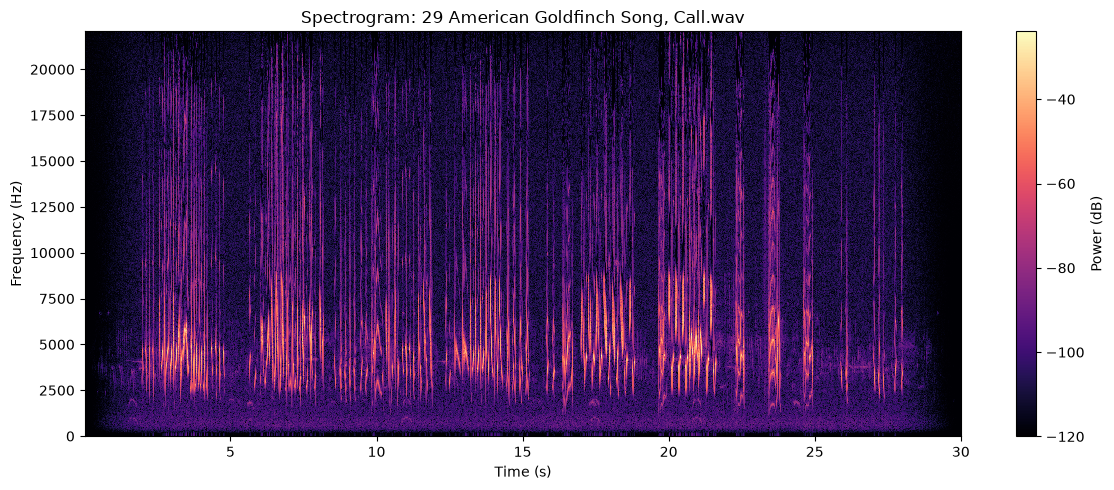

In [19]:
plot_spectrogram("data/wav/29 American Goldfinch Song, Call.wav")